## NBA Player Minutes Predictor - XGBoost Quantile
**- Owner:** Alex

**- Status:** Exploration only

**- Last Updated:** 10/26/26

**- Baseline:** 

- Loaded model pinball q50 (holdout): 2.218

- Loaded model 80% coverage (holdout): 79.9%

### Question

**Does player team spread or game total lower walk-forward q50 pinball below saved baseline?**

### Decision Criteria
**- Primary metric:** q50 pinball (minutes) on the walk-forward folds. Lower than 2.226 is better. Add one column in the play cell. Keep it only if removing it raises pinball.

**- Secondary metric:** 80% interval (q10–q90) and 90% interval (q05–q95) coverage near their targets

**- Serving threshold:** none yet — exploration only

**- Guardrail:** same hyperparameters as the saved model. No quantile crossing. 2025-26 is scored once, after the feature is locked, and is never used to tune.

### Data Contract
**- Data:** nba_api, rotowire, and basketball reference

**- Unit:** one row per player-game (`game_id`, `player_id`)

**- Label:** minutes played (`minutes` > 0)

**- Split:** chronological. Train 2019-10-22 → 2025-04-13. Validate inside that pool. Hold out 2025-10-21 → 2026-04-12.


### Setup and Configurations

The functions this notebook runs live in `notebooks/nba/minutes/src/minutes_xgb`. Import that package to start another minutes notebook.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALYSIS_SRC = Path("src").resolve()
if not (ANALYSIS_SRC / "minutes_xgb").is_dir():
    ANALYSIS_SRC = Path.cwd() / "notebooks/nba/minutes/src"
if str(ANALYSIS_SRC) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_SRC))

from minutes_xgb.paths import ensure_repo_on_path, repo_root

ensure_repo_on_path()

from minutes_xgb import (
    ARTIFACT_STEM,
    HOLDOUT_SEASON,
    ID_COLS,
    MIN_FEATURES,
    MIN_TIERS,
    QUANTILES,
    ROLE_COL,
    TARGET_COL,
    XGB_PARAMS,
    build_miss_frame,
    build_model_frame,
    build_oos_predictions,
    compare_to_baselines,
    data_quality,
    exploratory_metadata,
    feature_consensus,
    feature_missingness,
    feature_outlier_table,
    format_data_quality,
    format_minutes_outliers,
    holdout_point_distribution,
    interval_sharpness,
    load_regular_season,
    loaded_holdout_scores,
    mean_absolute_shap,
    minutes_outlier_summary,
    miss_view,
    missingness_summary,
    monotone_shift,
    permutation_importance_table,
    plot_minutes,
    plot_missingness,
    plot_shap,
    positive_minutes,
    predicted_minute_tiers,
    quantile_calibration,
    quantile_crossing,
    regular_season_blocks,
    role_quantile_fallback,
    role_reading,
    rotation_team_games,
    score_predictions,
    season_coverage,
    season_missingness,
    slice_score,
    tail_calibration_rows,
    top_minute_rows,
    write_oos_predictions,
)
from models.shared.analysis import analyze_correlations, run_feature_ablation
from models.shared.artifacts import load_model_bundle, save_model_bundle
from models.shared.splits import prepare_splits
from models.shared.train import evaluate_holdout, run_timeseries_cv, run_walk_forward

ROOT = repo_root()
pd.set_option("display.max_columns", None)


In [2]:
print(f"Holdout season: {HOLDOUT_SEASON}")
print(f"Config features ({len(MIN_FEATURES)}): {', '.join(MIN_FEATURES)}")
print(f"Quantiles: {QUANTILES}")

Holdout season: 2026-27
Config features (16): starting, starter_rank, start_rate_10, season_start_rate, starter_min_missing_teammates, total_stars_active, min_avg_lN, min_lag_1, min_ewm_hl_10, player_days_since_appearance, player_appearances_prev_7d, min_p80_10, min_p80_minus_p20_10, is_home, min_mean_vs_opp, games_vs_opp
Quantiles: [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]


### Data

In [3]:
df = load_regular_season(ROOT)
df.sample(5)


,season_year,player_id,player_name,nickname,team_id,team_abbreviation,team_name,game_id,game_date,matchup,wl,min,fgm,fga,fg_pct,fg3_m,fg3_a,fg3_pct,ftm,fta,ft_pct,oreb,dreb,reb,ast,tov,stl,blk,blka,pf,pfd,pts,plus_minus,nba_fantasy_pts,dd2,td3,wnba_fantasy_pts,fp_high_score,available_flag,min_sec,team_count,e_off_rating,off_rating,sp_work_off_rating,e_def_rating,def_rating,sp_work_def_rating,e_net_rating,net_rating,sp_work_net_rating,ast_pct,ast_to,ast_ratio,oreb_pct,dreb_pct,reb_pct,tm_tov_pct,e_tov_pct,efg_pct,ts_pct,usg_pct,e_usg_pct,e_pace,pace,pace_per40,sp_work_pace,pie,poss,fgm_pg,fga_pg,team_city,team_tricode,team_slug,first_name,family_name,name_i,player_slug,start_position,comment,jersey_num,minutes,spd,dist,orbc,drbc,rbc,tchs,sast,ftast,pass,assists,cfgm,cfga,cfg_pct,ufgm,ufga,uncontested_field_goals_percentage,field_goal_percentage,dfgm,dfga,dfg_pct,team_fgm,team_fga,team_fg_pct,team_fg3_m,team_fg3_a,team_fg3_pct,team_ftm,team_fta,team_ft_pct,team_oreb,team_dreb,team_reb,team_ast,team_tov,team_stl,team_blk,team_blka,team_pf,team_pfd,team_pts,team_plus_minus,team_e_off_rating,team_off_rating,team_e_def_rating,team_def_rating,team_e_net_rating,team_net_rating,team_ast_pct,team_ast_to,team_ast_ratio,team_oreb_pct,team_dreb_pct,team_reb_pct,team_tm_tov_pct,team_efg_pct,team_ts_pct,team_e_pace,team_pace,team_pace_per40,team_poss,team_pie,opp_team_id,opp_fgm,opp_fga,opp_fg_pct,opp_fg3_m,opp_fg3_a,opp_fg3_pct,opp_ftm,opp_fta,opp_ft_pct,opp_oreb,opp_dreb,opp_reb,opp_ast,opp_tov,opp_stl,opp_blk,opp_blka,opp_pf,opp_pfd,opp_pts,opp_plus_minus,opp_e_off_rating,opp_off_rating,opp_e_def_rating,opp_def_rating,opp_e_net_rating,opp_net_rating,opp_ast_pct,opp_ast_to,opp_ast_ratio,opp_oreb_pct,opp_dreb_pct,opp_reb_pct,opp_tm_tov_pct,opp_efg_pct,opp_ts_pct,opp_e_pace,opp_pace,opp_pace_per40,opp_poss,opp_pie,season_type,pos,game_total,team_spread,player_team_spread,starting
150706,2025-26,1643257,Jayson Kent,Jayson,1610612757,POR,Portland Trail Blazers,0022501183,2026-04-10T00:00:00,POR vs. LAC,W,1.400000,0,0,0.000,0,0,0.000,0,0,0.000,0,1,1,0,0,0,0,0,0,0,0,-1,1.2,0,0,1.0,1.0,1,1:24,1,53.2,50.0,50.0,100.0,66.7,66.7,-46.8,-16.7,-16.7,0.000,0.0,0.0,0.000,0.500,0.500,0.0,0.0,0.000,0.000,0.000,0.000,66.51,85.71,71.43,85.71,-2.000,2,0.0,0.0,Portland,POR,blazers,Jayson,Kent,J. Kent,jayson-kent,,,,1.400000,3.14,0.08,0,1,1,1,0,0,1,0,0,0,0.000,0,0,0.000,0.000,0,0,0.000,37,83,0.446,12,39,0.308,30,35,0.857,14,32,46,23,15.0,12,7,3,15,27,116,19.0,116.7,122.1,101.8,102.1,14.9,20.0,0.622,1.53,16.8,0.426,0.750,0.589,0.158,0.518,0.589,97.3,95.0,79.17,95,0.650,1610612746,36,83,0.434,13,40,0.325,12,12,1.000,10,25,35,17,17.0,6,3,7,27,15,97,-19.0,101.8,102.1,116.7,122.1,-14.9,-20.0,0.472,1.00,13.8,0.250,0.574,0.411,0.179,0.512,0.549,97.3,95.0,79.17,95,0.350,Regular Season,SF,226.5,-1.5,-1.5,0
83968,2022-23,203081,Damian Lillard,Damian,1610612757,POR,Portland Trail Blazers,0022200631,2023-01-12T00:00:00,POR vs. CLE,L,40.200000,16,28,0.571,5,13,0.385,13,15,0.867,0,2,2,3,1,1,0,0,1,8,50,-2,58.9,0,0,62.0,61.0,1,40:12,1,115.5,114.0,114.0,117.8,117.6,117.6,-2.4,-3.7,-3.7,0.167,3.0,7.9,0.000,0.045,0.027,2.6,2.6,0.661,0.723,0.385,0.405,101.35,102.09,85.07,102.09,0.248,86,16.0,28.0,Portland,POR,blazers,Damian,Lillard,D. Lillard,damian-lillard,G,,0,40.200000,3.95,2.87,1,4,5,102,2,0,63,3,10,16,0.625,6,12,0.500,0.571,2,3,0.667,40,78,0.513,11,33,0.333,22,29,0.759,5,31,36,17,17.0,6,4,1,27,19,113,-6.0,110.0,110.8,117.1,116.7,-7.1,-5.9,0.425,1.00,13.5,0.171,0.714,0.467,0.167,0.583,0.623,102.2,102.0,85.00,102,0.430,1610612739,44,89,0.494,7,22,0.318,24,31,0.774,12,32,44,28,11.0,6,1,4,19,27,119,6.0,117.1,116.7,110.0,110.8,7.1,5.9,0.636,2.55,19.6,0.286,0.829,0.533,0.108,0.534,0.580,102.2,102.0,85.00,102,0.570,Regular Season,PG,224.0,1.0,1.0,1
144680,2024-25,201950,Jrue Holiday,Jrue,1610612738,BOS,Boston Celtics,0022400271,2024-11-24T00:00:00,BOS vs. MIN,W,36.516667,3,10,0.300,1,6,0.167,2,2,1.000,1,3,4,3,1,1,1,0,2,1,9,-4,23.3,0,0,21.0,25.0,1,36:31,1,104.2,108.6,108.6,109.5,115.9

In [4]:
print(format_data_quality(data_quality(df)))

Number of rows : 177707
Number of columns: 190
Number of Unique Players: 1214
Number of Unique Games: 8332
Total number of duplicates: 0
Missing Labels: 0
Missing Start Position: 0
Median Minutes: 23.633333333333333
Mean Minutes: 22.642
Max Minutes: 56.517
Standard Deviation of Minutes: 10.669
Skewness of Minutes: -0.279
Kurtosis of Minutes: -0.805
Percentage of players averaging 10+ minutes: 74.4%
Percentage of players averaging 20+ minutes: 34.3%
Percentage of players averaging 30+ minutes: 8.5%
Percentage of players averaging 35+ minutes: 0.9%


### Features

In [5]:
df = build_model_frame(df)
df['position_encoded'] = df['pos'].map({'PG': 1, 'SG': 2, 'SF': 3, 'PF': 4, 'C': 5})

In [6]:
import minutes_xgb.config as minutes_config

# Saved 14-feature model. 01's matchup columns stay off unless listed below.
PARKED_FEATURES = ("min_mean_vs_opp", "games_vs_opp")
LOCKED_FEATURES = [
    name for name in minutes_config.MIN_FEATURES if name not in PARKED_FEATURES
]
if len(LOCKED_FEATURES) != 14:
    raise RuntimeError(
        f"expected the saved 14-feature list, got {len(LOCKED_FEATURES)}: "
        f"{LOCKED_FEATURES}"
    )

# One column at a time. Both are already on the frame from the pregame line.
PLAY_FEATURES = [
    "player_team_spread"
]
missing = [name for name in PLAY_FEATURES if name not in df.columns]
if missing:
    raise KeyError(f"play features are not on the frame: {missing}")
overlap = sorted(set(PLAY_FEATURES) & set(LOCKED_FEATURES))
if overlap:
    raise ValueError(f"play features already in the locked list: {overlap}")
if len(PLAY_FEATURES) != len(set(PLAY_FEATURES)):
    raise ValueError(f"duplicate play features: {PLAY_FEATURES}")

MIN_FEATURES = [*LOCKED_FEATURES, *PLAY_FEATURES]
print(f"Locked ({len(LOCKED_FEATURES)}): {', '.join(LOCKED_FEATURES)}")
print(f"Playing: {', '.join(PLAY_FEATURES) if PLAY_FEATURES else '(none)'}")
print(f"This run ({len(MIN_FEATURES)}): {', '.join(MIN_FEATURES)}")

Locked (14): starting, starter_rank, start_rate_10, season_start_rate, starter_min_missing_teammates, total_stars_active, min_avg_lN, min_lag_1, min_ewm_hl_10, player_days_since_appearance, player_appearances_prev_7d, min_p80_10, min_p80_minus_p20_10, is_home
Playing: player_team_spread
This run (15): starting, starter_rank, start_rate_10, season_start_rate, starter_min_missing_teammates, total_stars_active, min_avg_lN, min_lag_1, min_ewm_hl_10, player_days_since_appearance, player_appearances_prev_7d, min_p80_10, min_p80_minus_p20_10, is_home, player_team_spread


In [7]:
print(df["total_stars_active"].value_counts().sort_index())


total_stars_active
0       482
1      4279
2     32072
3    140874
Name: count, dtype: int64


In [8]:
print(f"Number of features: {len(MIN_FEATURES)}")
print(f"Number of nulls: {df[MIN_FEATURES].isna().sum().sum()}")


Number of features: 15
Number of nulls: 37015


### Train/validation/test

In [9]:
df = positive_minutes(df)
print(f"After filtering minutes: {len(df):,} rows")

splits = prepare_splits(
    df,
    holdout_season=HOLDOUT_SEASON,
    features=MIN_FEATURES,
    target_col=TARGET_COL,
    id_cols=ID_COLS,
    role_col=ROLE_COL,
    extra_keep=["minutes", "pts", "min_ewm_hl_10"],
)
ppm_df = splits["ppm_df"]
ppm_holdout = splits["ppm_holdout"]
X = splits["X"]
y = splits["y"]


After filtering minutes: 177,679 rows
Train pool (excl. 2026-27) : 176,710 rows
Holdout   (2026-27)        : 969 rows
Date range (train)   : 2019-10-22 → 2026-04-12
Date range (holdout) : 2026-10-20 → 2026-10-25


### EDA

Appearance rows: 177,679
Features with a null: 10 / 15
Rows with any null feature: 14,543 (8.2%)


,n_missing,pct_missing
min_avg_lN,6344,3.57
min_p80_10,5721,3.22
min_p80_minus_p20_10,5721,3.22
player_days_since_appearance,4336,2.44
season_start_rate,4334,2.44
player_team_spread,4197,2.36
starter_min_missing_teammates,2705,1.52
start_rate_10,1214,0.68
min_lag_1,1214,0.68
min_ewm_hl_10,1214,0.68


,min_avg_lN,min_p80_10,min_p80_minus_p20_10,player_days_since_appearance,season_start_rate,player_team_spread,starter_min_missing_teammates,start_rate_10,min_lag_1,min_ewm_hl_10
season_year,,,,,,,,,,
2019-20,3.5,11.5,11.5,2.4,2.4,7.7,1.4,2.4,2.4,2.4
2020-21,3.4,2.3,2.3,2.3,2.3,0.0,1.4,0.5,0.5,0.5
2021-22,3.4,2.3,2.3,2.3,2.3,2.3,1.3,0.5,0.5,0.5
2022-23,3.2,1.6,1.6,2.1,2.1,0.7,1.3,0.3,0.3,0.3
2023-24,3.4,1.8,1.8,2.2,2.2,3.9,1.3,0.4,0.4,0.4
2024-25,3.4,2.0,2.0,2.2,2.2,0.2,1.4,0.4,0.4,0.4
2025-26,3.3,1.9,1.9,2.2,2.2,2.3,1.3,0.4,0.4,0.4
2026-27,41.3,9.5,9.5,41.3,41.3,0.0,35.6,4.3,4.3,4.3


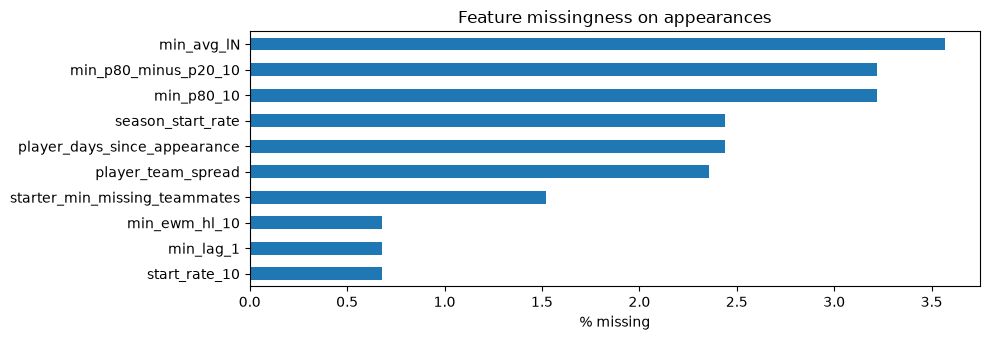

In [10]:
miss = feature_missingness(df, MIN_FEATURES)
print(missingness_summary(df, MIN_FEATURES))
display(miss)
season_miss = season_missingness(df, miss)
if season_miss.empty:
    print("Every selected feature is complete on this frame.")
else:
    display(season_miss)
    plot_missingness(miss)
    plt.show()


n=177,679  min=0.02  p50=23.63  max=56.52
Tukey fence [-9.27, 55.59]  outside=4 (0.0%)
Player minutes above 48 (overtime range): 81


,season_year,game_date,player_name,minutes,starting
62367,2021-22,2022-01-29,Pascal Siakam,56.516667,1
142386,2021-22,2022-01-29,Scottie Barnes,56.333333,1
71736,2021-22,2022-01-29,OG Anunoby,55.816667,1
92387,2021-22,2022-01-29,Gary Trent Jr.,55.650000,1
127003,2022-23,2023-03-05,Immanuel Quickley,55.100000,1
124024,2023-24,2024-04-07,Tyrese Maxey,53.950000,1
64916,2021-22,2022-01-29,Fred VanVleet,53.516667,1
156009,2024-25,2025-04-01,Christian Braun,53.166667,1


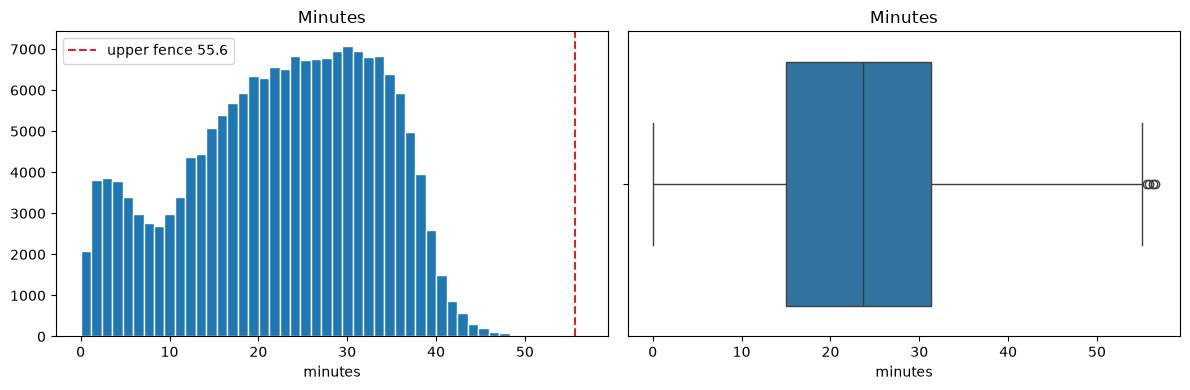

Binary inputs are omitted. A point is outside when it is past 1.5 IQR from the quartiles.


,feature,n,pct_outside,fence_low,fence_high,min,p50,max
0,player_days_since_appearance,173343,10.02,0.50,4.50,1.00,2.00,30.00
1,player_appearances_prev_7d,177679,7.97,0.50,4.50,0.00,3.00,5.00
2,min_p80_minus_p20_10,171958,3.09,-1.84,17.60,0.32,7.59,38.59
3,starter_min_missing_teammates,174974,2.00,-47.12,78.53,0.00,0.00,177.64
4,player_team_spread,173482,0.04,-23.25,22.75,-25.50,-1.00,25.50
5,starter_rank,177679,0.00,-7.50,20.50,1.00,7.00,22.00
6,start_rate_10,176465,0.00,-1.50,2.50,0.00,0.30,1.00
7,season_start_rate,173345,0.00,-1.50,2.50,0.00,0.28,1.00
8,min_avg_lN,171335,0.00,-6.06,51.99,0.00,23.37,48.89
9,min_lag_1,176465,0.00,-9.13,55.53,0.00,23.68,56.52


In [11]:
outlier_stats = minutes_outlier_summary(df)
print(format_minutes_outliers(outlier_stats))
display(top_minute_rows(df))
plot_minutes(df, float(outlier_stats["fence_high"]))
plt.show()
print(
    "Binary inputs are omitted. A point is outside when it is past "
    "1.5 IQR from the quartiles."
)
display(feature_outlier_table(df, MIN_FEATURES))


In [12]:
coverage = season_coverage(df, MIN_FEATURES)
print(f"Seasons: {len(coverage)}  rows: {int(coverage['rows'].sum()):,}")
display(coverage)


Seasons: 8  rows: 177,679


,rows,players,games,first_game,last_game,pct_rows_complete,mean_missing_features
season_year,,,,,,,
2019-20,22387,529,1059,2019-10-22,2020-08-14,80.5,0.47
2020-21,23053,540,1080,2020-12-22,2021-05-16,94.8,0.15
2021-22,26035,605,1230,2021-10-19,2022-04-10,92.9,0.18
2022-23,25892,539,1230,2022-10-18,2023-04-09,95.0,0.14
2023-24,26393,572,1230,2023-10-24,2024-04-14,91.5,0.18
2024-25,26302,569,1230,2024-10-22,2025-04-13,95.0,0.14
2025-26,26648,582,1230,2025-10-21,2026-04-12,93.1,0.16
2026-27,969,400,43,2026-10-20,2026-10-25,53.8,1.91


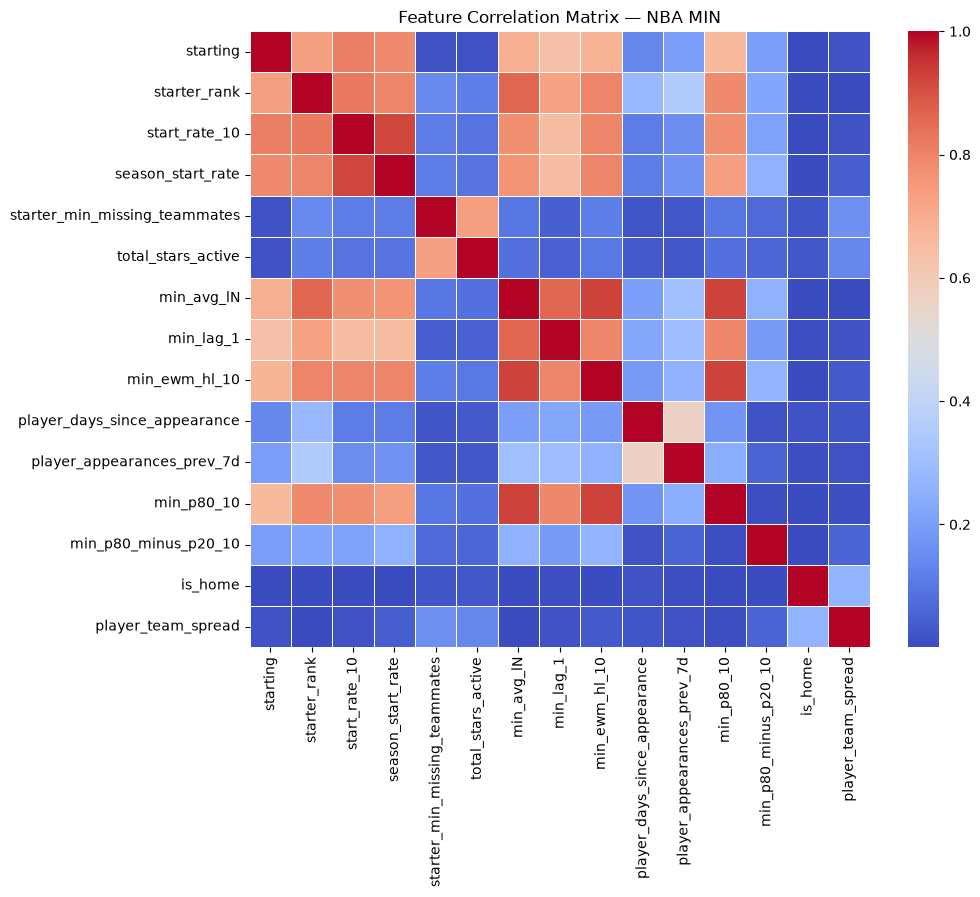

--- High Correlation Report (Threshold > 0.95) ---
No features exceed the correlation threshold.


[]

In [13]:
correlated_features = analyze_correlations(
    df, MIN_FEATURES, title="Feature Correlation Matrix — NBA MIN"
)
correlated_features


### Models

In [14]:
# Hyperparameter tuning
# Leave commented if you don't want to retune the model

import importlib
import models.shared.train as train

importlib.reload(train)
tune_xgb_quantile = train.tune_xgb_quantile

result = tune_xgb_quantile(X, y, n_trials=50, n_splits=4)
XGB_PARAMS = result["best_params"]

[I 2026-10-26 07:11:05,567] A new study created in memory with name: no-name-2cc9dcb0-3ea6-4a1b-858e-ffd41c2bf5fa


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-10-26 07:11:27,583] Trial 0 finished with value: 2.289852850480866 and parameters: {'n_estimators': 1062, 'max_depth': 12, 'learning_rate': 0.08960785365368121, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.5780093202212182, 'reg_alpha': 0.0037758875456826873, 'reg_lambda': 0.0016400214911202306, 'min_child_weight': 9}. Best is trial 0 with value: 2.289852850480866.
[I 2026-10-26 07:12:33,571] Trial 1 finished with value: 2.275923600529954 and parameters: {'n_estimators': 1402, 'max_depth': 10, 'learning_rate': 0.010636066512540286, 'subsample': 0.9849549260809971, 'colsample_bytree': 0.9162213204002109, 'reg_alpha': 0.00610149136730271, 'reg_lambda': 0.004705059281907649, 'min_child_weight': 2}. Best is trial 1 with value: 2.275923600529954.
[I 2026-10-26 07:12:57,052] Trial 2 finished with value: 2.2493920360863253 and parameters: {'n_estimators': 956, 'max_depth': 8, 'learning_rate': 0.03647316284911211, 'subsample': 0.645614570099021, 'colsample_bytree': 0.80592644

In [15]:
tscv_results = run_timeseries_cv(
    X, y, ppm_df,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=MIN_TIERS,
    quantiles=QUANTILES,
)
wf = run_walk_forward(
    X, y, ppm_df,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=MIN_TIERS,
    quantiles=QUANTILES,
    n_folds=5,
)

wf_results = wf["wf_results"]
models_last = wf["models_last"]
preds_last = wf["preds_last"]
X_val_last = wf["X_val_last"]
y_val_last = wf["y_val_last"]
starting_last = wf["starting_last"]
last_fold = wf["last_fold"]


── Phase 1: TimeSeriesSplit (XGBoost) ──────────────────────────

TSCV fold 1
  n=29451
  pinball  | q0.05=0.608  q0.10=1.017  q0.20=1.600  q0.30=1.971  q0.40=2.182  q0.50=2.245  q0.60=2.175  q0.70=1.958  q0.80=1.580  q0.90=0.997  q0.95=0.596
  coverage | 80%=78.8% (target 80%)  90%=89.1% (target 90%)
  Starters   | n=13799 | pinball q50: 2.109 | 80% coverage: 78.9%
  Bench      | n=15652 | pinball q50: 2.366 | 80% coverage: 78.6%
  minute tiers by predicted q50
  <15 min    | n= 6591 | pinball q50: 2.370 | 80% coverage: 78.8%
  15-24 min  | n= 8204 | pinball q50: 2.423 | 80% coverage: 78.7%
  24-31 min  | n= 7115 | pinball q50: 2.289 | 80% coverage: 78.8%
  31+ min    | n= 7541 | pinball q50: 1.901 | 80% coverage: 78.9%

TSCV fold 2
  n=29451
  pinball  | q0.05=0.634  q0.10=1.048  q0.20=1.630  q0.30=1.999  q0.40=2.200  q0.50=2.262  q0.60=2.185  q0.70=1.965  q0.80=1.586  q0.90=1.002  q0.95=0.598
  coverage | 80%=78.3% (target 80%)  90%=88.6% (target 90%)
  Starters   | n=14031 | pinbal

### Conformal calibration

Walk-forward out-of-fold rows only. Nothing here is fit on the 2025-26 holdout.

In [17]:
# One-sided conformal offsets on walk-forward OOF.
# Base knots are the sorted booster output, with each fold's cold-start
# role quantiles taken from that fold's training dates (the early-stopping
# tail is included there, and is not used as a calibration score).

from minutes_xgb.calibration import (
    calibration_table,
    fold_base_knots,
    nested_offset_backtest,
    oof_leakage_table,
    oof_player_games,
)
from minutes_xgb.config import N_BOOT, SEED
from models.shared.splits import date_walk_forward_folds
from src.models.settlement import maximum_minutes

MIN_N = 300
MAX_MINUTES = maximum_minutes("nba")

oof = wf["oof"].copy()
oof_player_games(oof, ppm_df)
n_folds = int(oof["fold_id"].nunique())
leak = oof_leakage_table(
    oof, ppm_df, date_walk_forward_folds(ppm_df, n_folds=n_folds)
)
display(leak)

base, group = fold_base_knots(
    oof, ppm_df, [result["train_mask"] for result in wf_results]
)
print(pd.Series(group).value_counts().to_string())
y = oof["minutes"].to_numpy(dtype=float)
dates = pd.to_datetime(oof["game_date"]).to_numpy()
starting = oof["starting"].to_numpy()
oof = oof.reset_index(drop=True)
base = base.reset_index(drop=True)

print(
    f"\nGo/no-go on base knots. delta = P(y <= q) - tau, "
    f"with {N_BOOT:,} date-clustered resamples, seed {SEED}."
)
go_nogo = calibration_table(
    y, dates, base, group, starting=starting, n_boot=N_BOOT, seed=SEED
)
display(go_nogo.round(4))

backtest = nested_offset_backtest(
    oof,
    base,
    group,
    folds=(3, 4),
    min_n=MIN_N,
    max_minutes=MAX_MINUTES,
    n_boot=N_BOOT,
    seed=SEED,
)
offset_tables = backtest["offset_tables"]
nested = backtest["nested"]
deltas = backtest["deltas"]
scores = backtest["scores"]
offset_flags = backtest["flags"]
for fold_id, table in offset_tables.items():
    print(f"\nOffsets fit on folds before {fold_id}")
    fold_counts = (
        backtest["counts"].loc[lambda frame: frame["fold"].eq(fold_id)].set_index("group")["n"]
    )
    print("rows per group:\n" + fold_counts.sort_index().to_string())
    omitted = fold_counts[fold_counts < MIN_N]
    if len(omitted):
        print("omitted (n < min_n):\n" + omitted.to_string())
    display(table.round(3))

print(
    "\nNested backtest, folds 3-5. diff = calibrated - raw. "
    "Lower WIS, CRPS, and pinball are better."
)
display(nested.round(4))
display(
    deltas.pivot_table(
        index=["fold", "version", "group"], columns="knot", values="delta"
    ).round(4)
)
display(scores.round(4))
print("\nOffset stability across fits on folds before k = 3, 4, 5")
if offset_flags.empty:
    print("No group/knot swings by more than its mean absolute offset.")
else:
    display(offset_flags.round(3))


,fold,train_end,val_start,val_end,n,val_in_train,val_in_stop,dates_match
0,1,2023-01-26,2023-01-27,2023-12-12,17583,0,0,True
1,2,2023-12-12,2023-12-13,2024-04-09,18184,0,0,True
2,3,2024-04-09,2024-04-10,2025-02-10,17941,0,0,True
3,4,2025-02-10,2025-02-11,2025-12-15,17769,0,0,True


15-24         18442
31+           18239
<15           17330
24-31         17176
cold_start      290

Go/no-go on base knots. delta = P(y <= q) - tau, with 2,000 date-clustered resamples, seed 42.


,n,empirical,target,delta,ci_low,ci_high,slice,check
0,71477,0.0531,0.05,0.0031,0.0011,0.0052,overall,q_0.05
1,71477,0.1047,0.10,0.0047,0.0021,0.0074,overall,q_0.10
2,71477,0.2048,0.20,0.0048,0.0014,0.0081,overall,q_0.20
3,71477,0.3030,0.30,0.0030,-0.0008,0.0073,overall,q_0.30
4,71477,0.3998,0.40,-0.0002,-0.0045,0.0044,overall,q_0.40
...,...,...,...,...,...,...,...,...
190,6167,0.7459,0.80,-0.0541,-0.0822,-0.0292,Apr,q_0.80
191,6167,0.8476,0.90,-0.0524,-0.0781,-0.0280,Apr,q_0.90
192,6167,0.9061,0.95,-0.0439,-0.0639,-0.0250,Apr,q_0.95
193,6167,0.7284,0.80,-0.0716,-0.1046,-0.0403,Apr,coverage_80



Offsets fit on folds before 3
rows per group:
group
15-24         9037
24-31         8516
31+           9449
<15           8650
cold_start     115
omitted (n < min_n):
group
cold_start    115


,n,q_0.05,q_0.10,q_0.20,q_0.30,q_0.40,q_0.50,q_0.60,q_0.70,q_0.80,q_0.90,q_0.95
group,,,,,,,,,,,,
<15,8650,-0.203,-0.258,-0.319,-0.336,-0.275,-0.300,-0.345,-0.252,-0.117,0.066,0.403
15-24,9037,0.091,-0.050,-0.094,-0.053,-0.084,-0.138,-0.091,-0.047,-0.005,0.036,0.223
24-31,8516,-0.013,-0.087,0.039,0.184,0.260,0.229,0.224,0.100,0.124,0.252,0.374
31+,9449,-0.388,-0.014,0.135,0.224,0.237,0.218,0.243,0.289,0.357,0.385,0.405



Offsets fit on folds before 4
rows per group:
group
15-24         13693
24-31         12586
31+           14114
<15           13112
cold_start      203
omitted (n < min_n):
group
cold_start    203


... (3 outputs left out)

knot                     q_0.05  q_0.10  q_0.20  q_0.30  q_0.40  q_0.50  \
fold version group                                                        
3    cal     15-24      -0.0032 -0.0087 -0.0106 -0.0118 -0.0158 -0.0129   
             24-31      -0.0014 -0.0044  0.0118  0.0182  0.0093  0.0182   
             31+        -0.0084  0.0005  0.0071  0.0215  0.0236  0.0190   
             <15        -0.0058 -0.0119 -0.0129 -0.0149 -0.0091 -0.0146   
             all        -0.0042 -0.0049  0.0004  0.0052  0.0039  0.0039   
             cold_start  0.1205  0.2409  0.3795  0.4500  0.4068  0.3636   
     raw     15-24      -0.0032 -0.0070 -0.0054 -0.0077 -0.0115 -0.0026   
             24-31      -0.0011 -0.0007  0.0096  0.0098 -0.0059 -0.0042   
             31+        -0.0028  0.0008  0.0002  0.0059  0.0006 -0.0012   
             <15         0.0065  0.0096  0.0127  0.0173  0.0182  0.0078   
             all         0.0004  0.0018  0.0058  0.0083  0.0024  0.0018   
             cold_start  0.1205  0.2409  0.3795  0.4500  0.4068  0.3636   
4    cal     15-24       0.0043 -0.0002 -0.0059 -0.0111 -0.0077 -0.0201   
             24-31      -0.0014 -0.0074 -0.0179 -0.0115  0.0050 -0.0017   
             31+        -0.0039  0.0001  0.0000  0.0038  0.0145  0.0166   
             <15         0.0041  0.0069 -0.0016 -0.0013 -0.0098 -0.0104   
             all         0.0010  0.0004 -0.0051 -0.0036  0.0018 -0.0031   
             cold_start  0.0420  0.1414  0.3057  0.3552  0.3126  0.2816   
     raw     15-24       0.0020 -0.0008 -0.0052 -0.0111 -0.0077 -0.0153   
             24-31      -0.0014 -0.0063 -0.0166 -0.0157 -0.0122 -0.0122   
             31+        -0.0010  0.0006 -0.0046 -0.0040  0.0024  0.0028   
             <15         0.0140  0.0209  0.0233  0.0227  0.0087  0.0052   
             all         0.0035  0.0039  0.0003 -0.0008 -0.0010 -0.0040   
             cold_start  0.0420  0.1414  0.3057  0.3552  0.3126  0.2816   

knot                     q_0.60  q_0.70  q_0.80  q_0.90  q_0.95  
fold version group                                               
3    cal     15-24      -0.0061  0.0034  0.0071  0.0006  0.0032  
             24-31       0.0189  0.0152  0.0199  0.0209  0.0158  
             31+         0.0264  0.0209  0.0244  0.0119  0.0011  
             <15        -0.0245 -0.0104 -0.0004  0.0043  0.0070  
             all         0.0049  0.0084  0.0134  0.0095  0.0067  
             cold_start  0.2864  0.2432  0.1659  0.1000  0.0500  
     raw     15-24      -0.0006  0.0051  0.0073 -0.0003 -0.0013  
             24-31       0.0059  0.0086  0.0123  0.0128  0.0085  
             31+         0.0030 -0.0038 -0.0047 -0.0033 -0.0072  
             <15         0.0011  0.0071  0.0052  0.0014  0.0002  
             all         0.0036  0.0053  0.0056  0.0028  0.0000  
             cold_start  0.2864  0.2432  0.1659  0.1000  0.0500  
4    cal     15-24      -0.0178 -0.0142 -0.0169 -0.0040 -0.0026  
             24-31       0.0041  0.0083  0.0024  0.0061  0.0029  
             31+         0.0223  0.0265  0.0242  0.0101  0.0005  
             <15        -0.0229 -0.0172 -0.0205 -0.0055 -0.0052  
             all        -0.0028  0.0013 -0.0024  0.0019 -0.0009  
             cold_start  0.2391  0.1851  0.1540  0.0770  0.0385  
     raw     15-24      -0.0144 -0.0106 -0.0135 -0.0049 -0.0052  
             24-31      -0.0061  0.0054  0.0004  0.0037  0.0001  
             31+         0.0058  0.0052  0.0046  0.0004 -0.0075  
             <15        -0.0066 -0.0082 -0.0162 -0.0057 -0.0086  
             all        -0.0045 -0.0013 -0.0055 -0.0012 -0.0049  
             cold_start  0.2391  0.1851  0.1540  0.0770  0.0385

,fold,n,reorder,pinball_q50_raw,pinball_q50_cal,wis_raw,wis_cal,wis_diff,wis_ci_low,wis_ci_high,crps_raw,crps_cal,crps_diff,crps_ci_low,crps_ci_high
0,3,17941,0.0057,2.1884,2.1898,3.0039,3.0062,0.0023,-0.0003,0.0050,3.0039,3.0062,0.0023,-0.0003,0.0050
1,4,17769,0.0040,2.2684,2.2688,3.1185,3.1189,0.0005,-0.0014,0.0024,3.1185,3.1189,0.0005,-0.0014,0.0024



Offset stability across fits on folds before k = 3, 4, 5


,group,knot,swing,mean_abs,offsets
0,15-24,q_0.10,0.094,0.047,"-0.050, 0.044"
1,15-24,q_0.20,0.069,0.059,"-0.094, -0.025"
2,15-24,q_0.30,0.057,0.028,"-0.053, 0.004"
3,15-24,q_0.40,0.082,0.043,"-0.084, -0.002"
4,15-24,q_0.80,0.052,0.031,"-0.005, -0.057"
5,24-31,q_0.05,0.015,0.008,"-0.013, 0.002"
6,24-31,q_0.20,0.077,0.038,"0.039, -0.038"
7,24-31,q_0.70,0.067,0.067,"0.100, 0.033"
8,24-31,q_0.80,0.097,0.075,"0.124, 0.027"
9,24-31,q_0.90,0.174,0.165,"0.252, 0.078"


In [18]:
wf_pinball, wf_coverage = score_predictions(
    y_val_last, preds_last, last_fold["fold"]
)
display(wf_pinball.round(4))
display(wf_coverage.round(4))


,split,quantile,pinball
0,WF fold 4 (2025-02-10 → 2025-12-15),0.05,0.6228
1,WF fold 4 (2025-02-10 → 2025-12-15),0.10,1.0352
2,WF fold 4 (2025-02-10 → 2025-12-15),0.20,1.6212
3,WF fold 4 (2025-02-10 → 2025-12-15),0.30,1.9947
4,WF fold 4 (2025-02-10 → 2025-12-15),0.40,2.1978
5,WF fold 4 (2025-02-10 → 2025-12-15),0.50,2.2607
6,WF fold 4 (2025-02-10 → 2025-12-15),0.60,2.1871
7,WF fold 4 (2025-02-10 → 2025-12-15),0.70,1.9693
8,WF fold 4 (2025-02-10 → 2025-12-15),0.80,1.5951
9,WF fold 4 (2025-02-10 → 2025-12-15),0.90,1.0174


,split,interval,coverage,target
0,WF fold 4 (2025-02-10 → 2025-12-15),80%,0.7951,0.8
1,WF fold 4 (2025-02-10 → 2025-12-15),90%,0.8915,0.9


In [19]:
holdout = evaluate_holdout(
    ppm_df,
    ppm_holdout,
    features=MIN_FEATURES,
    target_col=TARGET_COL,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=MIN_TIERS,
    wf_results=wf_results,
    quantiles=QUANTILES,
    fold_label=f"{HOLDOUT_SEASON} Blind Holdout",
)
models_ho = holdout["models_ho"]
preds_ho = holdout["preds_ho"]
ho_metrics = holdout["ho_metrics"]
X_ho = holdout["X_ho"]
y_ho = holdout["y_ho"]

ho_pinball, ho_coverage = score_predictions(
    y_ho, preds_ho, f"{HOLDOUT_SEASON} holdout"
)
display(ho_pinball.round(4))
display(ho_coverage.round(4))


── 2026-27 Blind Holdout ─────────────────────────────────────────────────
  Train pool: last 10% of training dates for early-stopping only; predict holdout (never in eval_set).

2026-27 Blind Holdout
  n=  969
  pinball  | q0.05=0.618  q0.10=1.056  q0.20=1.660  q0.30=2.014  q0.40=2.199  q0.50=2.243  q0.60=2.174  q0.70=1.944  q0.80=1.573  q0.90=0.986  q0.95=0.584
  coverage | 80%=78.3% (target 80%)  90%=88.9% (target 90%)
  Starters   | n=  430 | pinball q50: 2.066 | 80% coverage: 78.6%
  Bench      | n=  539 | pinball q50: 2.385 | 80% coverage: 78.1%
  minute tiers by predicted q50
  <15 min    | n=  261 | pinball q50: 2.490 | 80% coverage: 76.2%
  15-24 min  | n=  274 | pinball q50: 2.340 | 80% coverage: 79.2%
  24-31 min  | n=  251 | pinball q50: 2.218 | 80% coverage: 75.3%
  31+ min    | n=  183 | pinball q50: 1.781 | 80% coverage: 84.2%

───────────────────────────────────────────────────────
  Walk-forward pinball q50 (mean) : 2.223
  Holdout pinball q50             : 2.243
  Pin

,split,quantile,pinball
0,2026-27 holdout,0.05,0.6181
1,2026-27 holdout,0.10,1.0556
2,2026-27 holdout,0.20,1.6600
3,2026-27 holdout,0.30,2.0144
4,2026-27 holdout,0.40,2.1986
5,2026-27 holdout,0.50,2.2433
6,2026-27 holdout,0.60,2.1737
7,2026-27 holdout,0.70,1.9436
8,2026-27 holdout,0.80,1.5730
9,2026-27 holdout,0.90,0.9863


,split,interval,coverage,target
0,2026-27 holdout,80%,0.7833,0.8
1,2026-27 holdout,90%,0.8885,0.9


### Date-tail holdout, raw beside calibrated

Early stopping uses the last 10% of training dates. Offsets are the all-fold walk-forward table. The 2025-26 rows are scored, not fit.


In [21]:
# 8c. Date-tail holdout, raw knots beside calibrated knots.
# Offsets and tail tables are fit on walk-forward folds 1-4, which now
# include 2025-26. Dates on or after 2026-10-20 stay out. Raw is the
# booster output. Calibrated is sort, cold-start fallback, offset, sort, clip.

from minutes_xgb.calibration import fold_base_knots
from minutes_xgb.config import MIN_TIERS, N_BOOT, QUANTILES, SEED
from minutes_xgb.scoring import (
    holdout_point_distribution,
    interval_sharpness,
    predicted_minute_tiers,
    quantile_calibration,
    quantile_crossing,
    tail_calibration_rows,
    wis_values,
)
from minutes_xgb.slices import regular_season_blocks, slice_score
from models.shared.conformal import (
    apply_offsets,
    base_knots,
    calibration_group,
    calibration_payload,
    fit_offsets,
    role_quantile_table,
)
from models.shared.metrics import paired_date_bootstrap
import importlib
import models.shared.minutes_sampler as minutes_sampler

importlib.reload(minutes_sampler)
from models.shared.minutes_sampler import (
    build_tail_tables,
    save_tail_sidecar,
    tail_miss_rates,
    within_miss_rate_band,
)
from src.models.settlement import maximum_minutes

MIN_N = 300
MAX_MINUTES = maximum_minutes("nba")
oof = wf["oof"].copy()
knots = [f"q_{level:.2f}" for level in QUANTILES]
levels = {key: float(key.split("_", 1)[1]) for key in knots}

print(
    "Previous row-tail holdout (saved notebook run, last 10% of rows): "
    "q50 pinball 2.220, 80% coverage 80.0%, 90% coverage 89.6%."
)
print(
    "Date-tail holdout (last 10% of training dates): "
    f"q50 pinball {ho_metrics['pinball']:.3f}, "
    f"80% coverage {ho_metrics['coverage_80pct']:.1%}, "
    f"90% coverage {ho_metrics['coverage_90pct']:.1%}."
)

base_oof, group_oof = fold_base_knots(
    oof, ppm_df, [result["train_mask"] for result in wf_results]
)
offsets_all = fit_offsets(base_oof, oof["minutes"], group_oof, levels, min_n=MIN_N)
oof_cal = apply_offsets(base_oof, group_oof, offsets_all, MAX_MINUTES)
role_quantiles = role_quantile_table(ppm_df[["starting", "minutes"]], QUANTILES)
base_ho = base_knots(
    preds_ho,
    ppm_holdout["starting"],
    ppm_holdout["min_lag_1"],
    role_quantiles=role_quantiles,
)
group_ho = calibration_group(base_ho["q_0.50"], ppm_holdout["min_lag_1"])
preds_ho_cal = apply_offsets(base_ho, group_ho, offsets_all, MAX_MINUTES)
calibration_record = calibration_payload(
    offsets_all,
    group_oof,
    oof["game_date"],
    min_n=MIN_N,
    role_quantiles=role_quantiles,
    max_minutes=MAX_MINUTES,
)
print("OOF calibration rows", calibration_record["date_start"], "→", calibration_record["date_end"])
print("row counts", calibration_record["row_counts"])
display(offsets_all.round(3))

raw_map = {key: np.asarray(preds_ho[key], dtype=float) for key in knots}
cal_map = {key: preds_ho_cal[key].to_numpy(dtype=float) for key in knots}
base_map = {key: base_ho[key].to_numpy(dtype=float) for key in knots}
shift = offsets_all.reindex(pd.Index(group_ho)).fillna(0.0)
shift.index = base_ho.index
added = base_ho[knots].to_numpy() + shift[knots].to_numpy()
reorder = float(np.mean(np.any(np.diff(added, axis=1) < 0, axis=1)))
raw_cross, raw_n, _ = quantile_crossing(raw_map)
cal_cross, _, _ = quantile_crossing(cal_map)
print(
    f"Crossing rows: raw {raw_cross}/{raw_n} ({raw_cross / raw_n:.2%}), "
    f"calibrated {cal_cross}/{raw_n} ({cal_cross / raw_n:.2%}). "
    f"Second-sort reorder after the offset: {reorder:.2%}."
)

calibration_side = pd.concat(
    [
        quantile_calibration(y_ho, raw_map).assign(version="raw"),
        quantile_calibration(y_ho, cal_map).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("Holdout calibration. delta = P(y ≤ q) − τ")
display(
    calibration_side.pivot(index="quantile", columns="version", values="delta").round(4)
)

tiers = pd.concat(
    [
        predicted_minute_tiers(y_ho, raw_map, MIN_TIERS).assign(version="raw"),
        predicted_minute_tiers(y_ho, cal_map, MIN_TIERS).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("Predicted-minute tiers")
display(tiers.round(4))

point_table = pd.DataFrame(
    [
        holdout_point_distribution("raw", y_ho, raw_map),
        holdout_point_distribution("calibrated", y_ho, cal_map),
    ]
)
tail_table = pd.DataFrame(
    tail_calibration_rows("raw", y_ho, raw_map)
    + tail_calibration_rows("calibrated", y_ho, cal_map)
)
sharp = pd.concat(
    [
        interval_sharpness(y_ho, raw_map).assign(version="raw"),
        interval_sharpness(y_ho, cal_map).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("q50 RMSE and 11-knot CRPS. CRPS is twice the mean pinball at the trained knots.")
display(point_table.round(4))
print("Tail calibration. delta = empirical − nominal")
display(tail_table.round(4))
print("Interval sharpness")
display(sharp.round(4))

dates = pd.to_datetime(ppm_holdout["game_date"])
starting = ppm_holdout["starting"].to_numpy()
lag = ppm_holdout["min_lag_1"].to_numpy(dtype=float)
masks = {
    **regular_season_blocks(dates),
    "Confirmed starter": starting == 1,
    "Bench": starting == 0,
    "No prior game": ~np.isfinite(lag),
}
slice_rows = []
for name, mask in masks.items():
    chosen = np.asarray(mask, dtype=bool)
    slice_rows.append({**slice_score(name, chosen, y_ho, raw_map), "version": "raw"})
    slice_rows.append(
        {**slice_score(name, chosen, y_ho, cal_map), "version": "calibrated"}
    )
    if name == "No prior game":
        slice_rows.append(
            {**slice_score(name, chosen, y_ho, base_map), "version": "base fallback"}
        )
print("Calendar, role, and cold-start slices")
display(pd.DataFrame(slice_rows).round(4))


def _row_pinball(actual, pred, alpha=0.50):
    residual = np.asarray(actual, dtype=float) - np.asarray(pred, dtype=float)
    return np.where(residual >= 0, alpha * residual, (alpha - 1.0) * residual)


pin_ci = paired_date_bootstrap(
    _row_pinball(y_ho, raw_map["q_0.50"]),
    _row_pinball(y_ho, cal_map["q_0.50"]),
    dates,
    n_boot=N_BOOT,
    seed=SEED,
)
wis_ci = paired_date_bootstrap(
    wis_values(y_ho, raw_map),
    wis_values(y_ho, cal_map),
    dates,
    n_boot=N_BOOT,
    seed=SEED,
)
in_raw = (
    (np.asarray(y_ho, dtype=float) >= raw_map["q_0.10"])
    & (np.asarray(y_ho, dtype=float) <= raw_map["q_0.90"])
).astype(float)
in_cal = (
    (np.asarray(y_ho, dtype=float) >= cal_map["q_0.10"])
    & (np.asarray(y_ho, dtype=float) <= cal_map["q_0.90"])
).astype(float)
cov_ci = paired_date_bootstrap(in_raw, in_cal, dates, n_boot=N_BOOT, seed=SEED)
print(
    "Date-clustered 95% CI, calibrated − raw. "
    f"q50 pinball {pin_ci['diff']:+.4f} "
    f"[{pin_ci['ci_low']:+.4f}, {pin_ci['ci_high']:+.4f}]. "
    f"WIS {wis_ci['diff']:+.4f} "
    f"[{wis_ci['ci_low']:+.4f}, {wis_ci['ci_high']:+.4f}]. "
    f"80% coverage {cov_ci['diff']:+.4f} "
    f"[{cov_ci['ci_low']:+.4f}, {cov_ci['ci_high']:+.4f}]."
)

print(
    "\nTail miss rates on the next fold. Tables are fit on earlier calibrated folds only."
)
miss_rows = []
for k in (3, 4):
    past_ids = list(range(1, k))
    past = oof["fold_id"].isin(past_ids).to_numpy()
    offsets_k = fit_offsets(
        base_oof.loc[past],
        oof.loc[past, "minutes"],
        group_oof[past],
        levels,
        min_n=MIN_N,
    )
    past_cal = apply_offsets(
        base_oof.loc[past], group_oof[past], offsets_k, MAX_MINUTES
    )
    past_frame = oof.loc[
        past,
        [
            "fold_id",
            "game_date",
            "minutes",
            "starting",
            "early_stop",
            "train_tail_frac",
        ],
    ].copy()
    for column in knots:
        past_frame[column] = past_cal[column].to_numpy()
    build_tail_tables(
        past_frame.reset_index(drop=True),
        folds=past_ids,
        fold_ranges=wf["fold_ranges"],
        check_miss_rate=False,
        holdout_start="2026-10-20",
    )
    test = oof["fold_id"].to_numpy() == k
    test_cal = apply_offsets(
        base_oof.loc[test], group_oof[test], offsets_k, MAX_MINUTES
    )
    raw_lower, raw_upper = tail_miss_rates(
        oof.loc[test, "minutes"],
        base_oof.loc[test, "q_0.05"],
        base_oof.loc[test, "q_0.95"],
    )
    cal_lower, cal_upper = tail_miss_rates(
        oof.loc[test, "minutes"],
        test_cal["q_0.05"],
        test_cal["q_0.95"],
    )
    miss_rows.append(
        {
            "fold": k,
            "raw_lower": raw_lower,
            "raw_upper": raw_upper,
            "cal_lower": cal_lower,
            "cal_upper": cal_upper,
            "raw_in_band": within_miss_rate_band(raw_lower, raw_upper),
            "cal_in_band": within_miss_rate_band(cal_lower, cal_upper),
        }
    )
miss_rates = pd.DataFrame(miss_rows)
display(miss_rates.round(4))

ship = oof[
    ["fold_id", "game_date", "minutes", "starting", "early_stop", "train_tail_frac"]
].copy()
for column in knots:
    ship[column] = oof_cal[column].to_numpy()
tail_tables = build_tail_tables(
    ship.reset_index(drop=True),
    folds=[1, 2, 3, 4],
    fold_ranges=wf["fold_ranges"],
    check_miss_rate=False,
    holdout_start="2026-10-20",
)
tail_path = ROOT / "models/saved_models/min_nba_tails_cal_2026-10-26.joblib"
save_tail_sidecar(tail_tables, tail_path)
print(f"Wrote calibrated tail tables to {tail_path.relative_to(ROOT)}")


Previous row-tail holdout (saved notebook run, last 10% of rows): q50 pinball 2.220, 80% coverage 80.0%, 90% coverage 89.6%.
Date-tail holdout (last 10% of training dates): q50 pinball 2.243, 80% coverage 78.3%, 90% coverage 88.9%.
OOF calibration rows 2023-01-27 → 2025-12-15
row counts {'cold_start': 290, '<15': 17330, '15-24': 18442, '24-31': 17176, '31+': 18239}


,q_0.05,q_0.10,q_0.20,q_0.30,q_0.40,q_0.50,q_0.60,q_0.70,q_0.80,q_0.90,q_0.95
group,,,,,,,,,,,
<15,-0.179,-0.226,-0.260,-0.271,-0.211,-0.219,-0.149,-0.098,0.002,0.066,0.308
15-24,0.090,0.044,0.006,0.054,0.021,0.007,0.011,0.008,0.029,0.070,0.187
24-31,0.025,0.016,0.056,0.145,0.197,0.160,0.113,0.004,0.016,0.034,0.089
31+,-0.090,-0.023,0.088,0.111,0.117,0.113,0.115,0.161,0.183,0.252,0.370


Crossing rows: raw 20/969 (2.06%), calibrated 0/969 (0.00%). Second-sort reorder after the offset: 0.31%.
Holdout calibration. delta = P(y ≤ q) − τ


version,calibrated,raw
quantile,,
0.05,0.0150,0.0099
0.10,0.0228,0.0197
0.20,0.0023,0.0012
0.30,-0.0110,-0.0203
0.40,-0.0037,-0.0171
0.50,-0.0015,-0.0150
0.60,0.0089,-0.0056
0.70,0.0090,-0.0024
0.80,0.0039,-0.0064


Predicted-minute tiers


,tier,n,share,pinball_q50,empirical_q50,coverage_80,coverage_90,mean_width_80,mean_width_90,version
0,<15 min,261,0.2693,2.4897,0.5402,0.7625,0.8736,16.7139,20.9487,raw
1,15-24 min,274,0.2828,2.3404,0.4453,0.7920,0.8832,15.3481,20.0156,raw
2,24-31 min,251,0.2590,2.2179,0.4861,0.7530,0.9004,13.3888,17.5799,raw
3,31+ min,183,0.1889,1.7812,0.4645,0.8415,0.9016,12.3398,16.1125,raw
4,<15 min,225,0.2322,2.4808,0.5200,0.7778,0.8800,16.6700,21.1101,calibrated
5,15-24 min,310,0.3199,2.5834,0.4903,0.7710,0.8710,16.3356,20.9921,calibrated
6,24-31 min,235,0.2425,2.2660,0.4979,0.7489,0.8979,13.3656,17.5988,calibrated
7,31+ min,199,0.2054,1.7263,0.4874,0.8492,0.9196,12.7326,16.7167,calibrated


... (7 outputs left out)

,slice,n,version,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,October–February,0,raw,NaN,NaN,NaN,NaN,NaN,NaN
1,October–February,0,calibrated,NaN,NaN,NaN,NaN,NaN,NaN
2,March 1–14,0,raw,NaN,NaN,NaN,NaN,NaN,NaN
3,March 1–14,0,calibrated,NaN,NaN,NaN,NaN,NaN,NaN
4,March 15–31,0,raw,NaN,NaN,NaN,NaN,NaN,NaN
5,March 15–31,0,calibrated,NaN,NaN,NaN,NaN,NaN,NaN
6,April regular season,969,raw,4.4865,-0.1171,0.4850,0.7833,14.6403,3.1001
7,April regular season,969,calibrated,4.6132,-0.4435,0.4985,0.7833,14.9530,3.1717
8,Confirmed starter,430,raw,4.1320,-0.2673,0.4605,0.7860,13.1067,2.8568
9,Confirmed starter,430,calibrated,4.0993,-0.4390,0.4767,0.7907,13.2370,2.8460


Date-clustered 95% CI, calibrated − raw. q50 pinball +0.0633 [+0.0313, +0.1163]. WIS +0.0716 [+0.0345, +0.1358]. 80% coverage +0.0000 [-0.0069, +0.0071].

Tail miss rates on the next fold. Tables are fit on earlier calibrated folds only.


,fold,raw_lower,raw_upper,cal_lower,cal_upper,raw_in_band,cal_in_band
0,3,0.0504,0.0500,0.0458,0.0433,True,True
1,4,0.0535,0.0549,0.0510,0.0509,True,True


Wrote calibrated tail tables to models/saved_models/min_nba_tails_cal_2026-10-26.joblib


In [22]:
calibration = quantile_calibration(y_ho, preds_ho)
print(f"{HOLDOUT_SEASON} holdout — empirical quantile calibration")
display(calibration.round(4))


2026-27 holdout — empirical quantile calibration


,quantile,target,empirical,delta
0,0.05,0.05,0.0599,0.0099
1,0.10,0.10,0.1197,0.0197
2,0.20,0.20,0.2012,0.0012
3,0.30,0.30,0.2797,-0.0203
4,0.40,0.40,0.3829,-0.0171
5,0.50,0.50,0.4850,-0.0150
6,0.60,0.60,0.5944,-0.0056
7,0.70,0.70,0.6976,-0.0024
8,0.80,0.80,0.7936,-0.0064
9,0.90,0.90,0.9030,0.0030


In [23]:
n_crossed, n_rows, crossing_pairs = quantile_crossing(preds_ho)
print(
    f"{HOLDOUT_SEASON} holdout quantile crossing: "
    f"{n_crossed:,} / {n_rows:,} rows ({n_crossed / n_rows:.1%})"
)
display(crossing_pairs.round(4))


2026-27 holdout quantile crossing: 20 / 969 rows (2.1%)


,lower,upper,crossing_rate
0,q_0.05,q_0.10,0.0000
1,q_0.10,q_0.20,0.0000
2,q_0.20,q_0.30,0.0021
3,q_0.30,q_0.40,0.0062
4,q_0.40,q_0.50,0.0031
5,q_0.50,q_0.60,0.0021
6,q_0.60,q_0.70,0.0031
7,q_0.70,q_0.80,0.0010
8,q_0.80,q_0.90,0.0041
9,q_0.90,q_0.95,0.0000


In [24]:
tier_report = predicted_minute_tiers(y_ho, preds_ho, MIN_TIERS)
print(f"{HOLDOUT_SEASON} holdout — minute tiers by predicted q50")
display(tier_report.round(4))


2026-27 holdout — minute tiers by predicted q50


,tier,n,share,pinball_q50,empirical_q50,coverage_80,coverage_90,mean_width_80,mean_width_90
0,<15 min,261,0.2693,2.4897,0.5402,0.7625,0.8736,16.7139,20.9487
1,15-24 min,274,0.2828,2.3404,0.4453,0.7920,0.8832,15.3481,20.0156
2,24-31 min,251,0.2590,2.2179,0.4861,0.7530,0.9004,13.3888,17.5799
3,31+ min,183,0.1889,1.7812,0.4645,0.8415,0.9016,12.3398,16.1125


In [25]:
score_table = pd.DataFrame([
    holdout_point_distribution("XGBoost", y_ho, preds_ho)
])
tail_calibration = pd.DataFrame(
    tail_calibration_rows("XGBoost", y_ho, preds_ho)
)
print(
    f"{HOLDOUT_SEASON} holdout — q50 RMSE and 11-knot CRPS\n"
    "  CRPS is twice the mean pinball across the trained knots"
)
display(score_table.round(4))
print(
    f"{HOLDOUT_SEASON} holdout — tail calibration\n"
    "  delta is empirical minus nominal. "
    "A positive delta means more outcomes landed in that tail than the quantile claims"
)
display(tail_calibration.round(4))


2026-27 holdout — q50 RMSE and 11-knot CRPS
  CRPS is twice the mean pinball across the trained knots


,model,rmse,crps
0,XGBoost,5.8533,3.1001


2026-27 holdout — tail calibration
  delta is empirical minus nominal. A positive delta means more outcomes landed in that tail than the quantile claims


,model,side,quantile,nominal,empirical,delta
0,XGBoost,lower,0.05,0.05,0.0599,0.0099
1,XGBoost,lower,0.10,0.10,0.1197,0.0197
2,XGBoost,upper,0.90,0.10,0.0970,-0.0030
3,XGBoost,upper,0.95,0.05,0.0516,0.0016


In [26]:
sharp_xgb = interval_sharpness(y_ho, preds_ho)
print(f"{HOLDOUT_SEASON} holdout — interval sharpness (minutes)")
display(sharp_xgb.round(4))


2026-27 holdout — interval sharpness (minutes)


,interval,coverage,target,mean_width,median_width
0,80%,0.7833,0.8,14.6403,14.0813
1,90%,0.8885,0.9,18.8989,18.2633


### Baseline

In [27]:
report = compare_to_baselines(
    y_ho,
    preds_ho,
    ppm_holdout,
    ppm_df,
    wf_results,
)
print("1. Point accuracy versus baselines")
print(
    f"Identical holdout rows: {report['paired_n']:,}  |  "
    f"dropped {report['dropped_n']:,} with a missing baseline  |  "
    f"{report['n_boot']:,} date-clustered resamples"
)
print(
    "Mean bias is actual minus predicted. "
    f"XGBoost q50 pinball {report['q50_pinball']:.4f}. "
    "That equals half the q50 MAE."
)
display(report["point_table"].round(3))
print(
    "Paired MAE difference, clustered by game date. "
    "Negative means XGBoost q50 is lower."
)
display(report["delta_table"].round(3))
print(
    "Walk-forward MAE is 2 × q50 pinball on every validation row. "
    "Baseline MAE drops rows with no prior."
)
display(report["fold_table"].round(3))

print("\n2. Distribution quality")
knots = ", ".join(report["wis_knots"]) if report["wis_knots"] else "median only"
print(f"WIS uses the trained knots only: {knots}, plus the q50 term.")
display(report["distribution"].round(4))
print(
    f"Best baseline MAE {report['best_mae']:.3f} "
    f"({report['best_name']}) is that point forecast's CRPS."
)

print("\n3. Calibration of every quantile")
display(report["calibration"].round(4))

print("\n4. Pregame-defined subgroups")
print("Minute tiers use predicted q50.")
display(report["subgroup_table"].round(3))

print("\n5. Tail failures")
display(report["tail_table"].round(4))
print("\nChecks from this frame")
for line in report["checks"]:
    print(f"  {line}")


1. Point accuracy versus baselines
Identical holdout rows: 927  |  dropped 42 with a missing baseline  |  2,000 date-clustered resamples
Mean bias is actual minus predicted. XGBoost q50 pinball 2.2306. That equals half the q50 MAE.


,model,mae,median_ae,mean_bias
0,Last-game minutes,6.644,4.733,-0.547
1,EWMA minutes,5.639,4.513,-1.873
2,Quantile XGBoost q50,4.461,3.495,-0.160


Paired MAE difference, clustered by game date. Negative means XGBoost q50 is lower.


,comparison,delta_mae,ci_low,ci_high
0,XGBoost q50 − Last-game minutes,-2.183,-3.581,-1.182
1,XGBoost q50 − EWMA minutes,-1.178,-1.397,-0.793


Walk-forward MAE is 2 × q50 pinball on every validation row. Baseline MAE drops rows with no prior.


,fold,n,model_mae,last_game,ewma,best_baseline,model_minus_best
0,WF fold 1 (2023-01-26 → 2023-12-12),17583,4.466,5.957,5.396,5.396,-0.930
1,WF fold 2 (2023-12-12 → 2024-04-09),18184,4.442,5.815,5.289,5.289,-0.848
2,WF fold 3 (2024-04-09 → 2025-02-10),17941,4.353,5.727,5.196,5.196,-0.843
3,WF fold 4 (2025-02-10 → 2025-12-15),17769,4.521,6.055,5.532,5.532,-1.011


... (5 outputs left out)

,model,group,n,mae,bias,wis,cov_80,width_80_mean,width_80_median,cov_90,width_90_mean,width_90_median
0,Quantile XGBoost,Confirmed starter,430,4.132,-0.267,2.857,0.786,13.107,12.642,0.900,17.103,16.620
1,Quantile XGBoost,Bench,539,4.769,0.003,3.294,0.781,15.864,15.930,0.879,20.332,20.145
2,Quantile XGBoost,Predicted q50 <15 min,261,4.979,-0.003,3.395,0.762,16.714,16.650,0.874,20.949,20.590
3,Quantile XGBoost,Predicted q50 15-24 min,274,4.681,0.124,3.266,0.792,15.348,15.137,0.883,20.016,19.638
4,Quantile XGBoost,Predicted q50 24-31 min,251,4.436,-0.191,3.043,0.753,13.389,12.877,0.900,17.580,17.006
5,Quantile XGBoost,Predicted q50 31+ min,183,3.562,-0.540,2.509,0.842,12.340,12.226,0.902,16.113,15.888
6,Quantile XGBoost,2026-10,969,4.487,-0.117,3.100,0.783,14.640,14.081,0.889,18.899,18.263



5. Tail failures


,model,threshold,rate,n
0,Quantile XGBoost,>5 min,0.3581,347
1,Quantile XGBoost,>10 min,0.0877,85
2,Quantile XGBoost,>15 min,0.0186,18



Checks from this frame
  Quantile XGBoost q50 observed rate 48.5%  (target about 48–52%)
  Quantile XGBoost largest |quantile gap| 2.0%
  XGBoost q50 vs EWMA minutes: delta MAE -1.178 [-1.397, -0.793]
  WIS 3.100 (XGBoost) vs best baseline CRPS/MAE 5.639
  walk-forward folds with XGBoost MAE below the best baseline: 4 / 4
  raw quantile crossing 2.06%


### Features Analysis

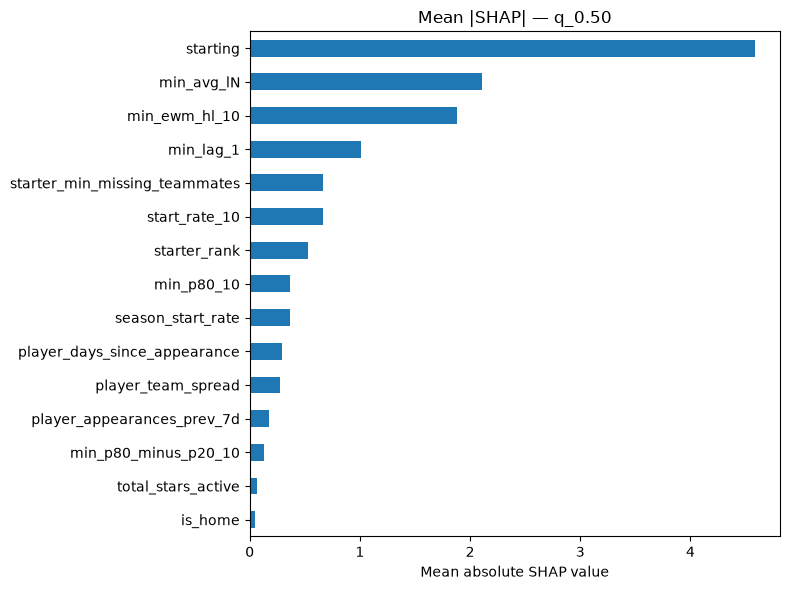

In [28]:
feat_imp = mean_absolute_shap(models_last["q_0.50"], X_val_last)
plot_shap(feat_imp)
plt.show()


In [29]:
pi_df, perm_result = permutation_importance_table(
    models_last["q_0.50"],
    X_val_last,
    y_val_last,
)
print(
    "Permutation importance (val set) — higher = more important, "
    "significant = p<0.05"
)
print(pi_df.to_string())


Permutation importance (val set) — higher = more important, significant = p<0.05
                          feature  importance      std  p_value  significant
1                        starting     0.96662  0.01403      0.0         True
2                      min_avg_lN     0.38661  0.00906      0.0         True
3                   min_ewm_hl_10     0.37963  0.00976      0.0         True
4                    starter_rank     0.30376  0.00673      0.0         True
5                       min_lag_1     0.13633  0.00466      0.0         True
6                   start_rate_10     0.09366  0.00361      0.0         True
7               season_start_rate     0.06683  0.00272      0.0         True
8   starter_min_missing_teammates     0.06010  0.00344      0.0         True
9                      min_p80_10     0.04598  0.00265      0.0         True
10             player_team_spread     0.03000  0.00192      0.0         True
11   player_days_since_appearance     0.02718  0.00239      0.0         

In [30]:
train_mask_last = last_fold["train_mask"]
val_mask_last = last_fold["val_mask"]
X_tr_last = X.loc[train_mask_last]
X_va_last = X.loc[val_mask_last]
y_tr_last = ppm_df.loc[train_mask_last, TARGET_COL]
y_va_last = ppm_df.loc[val_mask_last, TARGET_COL]

ablation_df = run_feature_ablation(
    MIN_FEATURES, X_tr_last, y_tr_last, X_va_last, y_va_last,
    xgb_params=XGB_PARAMS,
)


Baseline pinball q50 (all features): 2.2607
                          feature  ablated_pinball  delta_pinball
1                        starting           2.3627         0.1020
2                       min_lag_1           2.2795         0.0188
3                    starter_rank           2.2791         0.0184
4                   min_ewm_hl_10           2.2751         0.0144
5                      min_avg_lN           2.2736         0.0129
6              player_team_spread           2.2706         0.0100
7   starter_min_missing_teammates           2.2691         0.0085
8                   start_rate_10           2.2676         0.0069
9                      min_p80_10           2.2630         0.0023
10             total_stars_active           2.2625         0.0018
11   player_days_since_appearance           2.2625         0.0018
12     player_appearances_prev_7d           2.2621         0.0014
13              season_start_rate           2.2616         0.0010
14                        is_hom

In [31]:
feature_audit = feature_consensus(
    list(X_val_last.columns),
    feat_imp,
    pi_df,
    perm_result.importances,
    ablation_df,
)
print(feature_audit.to_string())


                          feature  mean_abs_shap  shap_rank  perm_rank  perm_importance  perm_importance_std   perm_pvalue  ablation_delta  shap_norm  perm_norm  consensus   keep
1                        starting       4.583893          1          1          0.96662              0.01403  7.267522e-55          0.1020   1.000000   1.000000   1.000000   True
2                      min_avg_lN       2.108533          2          2          0.38661              0.00906  7.857997e-49          0.0129   0.459987   0.399961   0.429974   True
3                   min_ewm_hl_10       1.877171          3          3          0.37963              0.00976  1.136416e-47          0.0144   0.409514   0.392740   0.401127   True
4                    starter_rank       0.529125          7          4          0.30376              0.00673  1.520364e-49          0.0184   0.115431   0.314250   0.214840   True
5                       min_lag_1       1.010830          4          5          0.13633              0.00

### Slice Analysis

In [32]:
dates = pd.to_datetime(ppm_holdout["game_date"])
raw_q = {key: np.asarray(pred, dtype=float) for key, pred in preds_ho.items()}
blocks = regular_season_blocks(dates)

print("1. April is late regular season, not the postseason")
holdout_season = df.loc[df["season_year"].astype("string").eq(str(HOLDOUT_SEASON))]
print(holdout_season["season_type"].astype("string").value_counts(dropna=False).to_string())
print(
    f"Holdout dates {dates.min().date()} → {dates.max().date()}. "
    "The silver store only has regular_season gamelogs, so playoff games are not in this test."
)
calendar = pd.DataFrame([
    slice_score(name, mask, y_ho, raw_q) for name, mask in blocks.items()
])
display(calendar.round(3))
print(
    "Limitation: April's higher MAE and lower 80% coverage is the last two weeks of the "
    "regular season. It is not a postseason effect, and the model has not been tested on playoff games."
)

print("\n2. Starter and bench mean bias versus median calibration")
starting = ppm_holdout["starting"].to_numpy()
role = pd.DataFrame([
    slice_score("Confirmed starter", starting == 1, y_ho, raw_q),
    slice_score("Bench", starting == 0, y_ho, raw_q),
])
display(role.round(3))
for _, row in role.iterrows():
    if row["n"] == 0:
        continue
    print(
        f"  {row['slice']}: bias {row['bias']:+.2f} min, "
        f"P(actual <= q50) {row['p_actual_le_q50']:.1%}. {role_reading(row)}."
    )

print("\n3. Monotone rearrangement")
preds_ho_mono, shift, before, after = monotone_shift(raw_q)
print(f"Crossing before {before:.2%} of rows; after rearrangement {after:.2%}.")
display(shift.round(4))
print("Simulate from preds_ho_mono. The saved trees stay raw; sort each row after predict.")

print("\n4. Cold-start and missing-baseline rows")
lag = ppm_holdout["min_lag_1"].to_numpy(dtype=float)
ewma = ppm_holdout["min_ewm_hl_10"].to_numpy(dtype=float)
cold = ~np.isfinite(lag)
missing_any = cold | ~np.isfinite(ewma)
print(
    f"Missing any baseline: {int(missing_any.sum()):,} | "
    f"no prior game (min_lag_1 missing): {int(cold.sum()):,}"
)
fallback_q = role_quantile_fallback(ppm_df, preds_ho_mono, starting, cold)
missing_table = pd.DataFrame([
    slice_score("No prior game, model", cold, y_ho, raw_q),
    slice_score("No prior game, role fallback", cold, y_ho, fallback_q),
    slice_score("Any missing baseline, model", missing_any, y_ho, raw_q),
])
display(missing_table.round(3))
print(
    "Live fallback: if min_lag_1 exists, predict with the quantile model and then "
    "sort that row into increasing quantile order. "
    "If min_lag_1 is missing, do not use the tree. Use the training-pool minute quantiles "
    "for the confirmed role (starter or bench). preds_ho_live applies that rule."
)
preds_ho_live = fallback_q


1. April is late regular season, not the postseason
season_type
Regular Season    969
Holdout dates 2026-10-20 → 2026-10-25. The silver store only has regular_season gamelogs, so playoff games are not in this test.


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,October–February,0,NaN,NaN,NaN,NaN,NaN,NaN
1,March 1–14,0,NaN,NaN,NaN,NaN,NaN,NaN
2,March 15–31,0,NaN,NaN,NaN,NaN,NaN,NaN
3,April regular season,969,4.487,-0.117,0.485,0.783,14.64,3.1


Limitation: April's higher MAE and lower 80% coverage is the last two weeks of the regular season. It is not a postseason effect, and the model has not been tested on playoff games.

2. Starter and bench mean bias versus median calibration


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,Confirmed starter,430,4.132,-0.267,0.460,0.786,13.107,2.857
1,Bench,539,4.769,0.003,0.505,0.781,15.864,3.294


  Confirmed starter: bias -0.27 min, P(actual <= q50) 46.0%. q50 is too low: actuals fall under the median less often than 50%.
  Bench: bias +0.00 min, P(actual <= q50) 50.5%. q50 is near 50%, so the mean bias is skew around a calibrated median.

3. Monotone rearrangement
Crossing before 2.06% of rows; after rearrangement 0.00%.


,quantile,mean_abs_shift,share_changed
0,q_0.05,0.0000,0.0000
1,q_0.10,0.0000,0.0000
2,q_0.20,0.0010,0.0031
3,q_0.30,0.0026,0.0083
4,q_0.40,0.0039,0.0103
5,q_0.50,0.0010,0.0052
6,q_0.60,0.0019,0.0062
7,q_0.70,0.0041,0.0052
8,q_0.80,0.0063,0.0052
9,q_0.90,0.0072,0.0041


Simulate from preds_ho_mono. The saved trees stay raw; sort each row after predict.

4. Cold-start and missing-baseline rows
Missing any baseline: 42 | no prior game (min_lag_1 missing): 42


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,"No prior game, model",42,5.045,0.830,0.500,0.738,18.702,3.422
1,"No prior game, role fallback",42,8.081,-6.392,0.786,0.667,22.718,5.154
2,"Any missing baseline, model",42,5.045,0.830,0.500,0.738,18.702,3.422


Live fallback: if min_lag_1 exists, predict with the quantile model and then sort that row into increasing quantile order. If min_lag_1 is missing, do not use the tree. Use the training-pool minute quantiles for the confirmed role (starter or bench). preds_ho_live applies that rule.


### Error Analysis

In [33]:
miss = build_miss_frame(df, ppm_holdout, preds_ho)
way_off = miss["abs_error"] >= 10
print(
    f"{HOLDOUT_SEASON} holdout: {int(way_off.sum()):,} / {len(miss):,} rows "
    f"missed by 10+ minutes ({way_off.mean():.1%}). "
    f"Median |error| {miss['abs_error'].median():.1f}."
)
print("actual − q50 > 0 means he played more than the median prediction.")


def show_misses(frame, title):
    print(title)
    display(miss_view(frame))


show_misses(
    miss.nsmallest(20, "error"),
    "\nPlayed much less than q50 (sat, foul trouble, blowout rest)",
)
show_misses(
    miss.nlargest(20, "error"),
    "\nPlayed much more than q50 (garbage time, overtime, unexpected run)",
)
biggest = pd.concat(
    [miss.nsmallest(20, "error"), miss.nlargest(20, "error")],
    ignore_index=True,
)
print("\nHints on those 40 misses")
print(biggest["hint"].replace("", "unlabeled").value_counts().to_string())
games = rotation_team_games(miss)
print("\nTeam-games where the most rotation players (q50 ≥ 15) missed by 10+ minutes")
display(
    games.head(15)[
        [
            "date",
            "game",
            "score",
            "wl",
            "margin",
            "ot",
            "n_rotation",
            "n_off_10",
            "mean_abs_error",
            "players_off_by_10",
        ]
    ]
)


2026-27 holdout: 85 / 969 rows missed by 10+ minutes (8.8%). Median |error| 3.6.
actual − q50 > 0 means he played more than the median prediction.

Played much less than q50 (sat, foul trouble, blowout rest)


,date,player,game,score,wl,actual_min,pred_q50,actual − q50,q10–q90,fouls,fouls_drawn,starting,pts,+/-,margin,last_game_min,pregame_|spread|,ot,hint
833,2026-10-25,Ivica Zubac,IND @ BKN,136-109,W,7.0,28.5,-21.4,21–35,1,1,1,2,6,27,23.6,5.5,False,blowout rest
341,2026-10-22,Cameron Johnson,DEN @ OKC,84-96,L,11.3,31.3,-19.9,24–37,2,0,1,5,0,-12,29.7,8.0,False,outside 10–90
532,2026-10-23,Jalen Duren,DET @ MIA,128-111,W,10.1,29.5,-19.3,22–36,0,0,1,4,12,17,28.0,1.5,False,blowout rest
916,2026-10-25,Cason Wallace,OKC vs. LAC,108-101,W,5.6,24.5,-18.8,19–30,0,1,1,4,2,7,24.0,16.5,False,outside 10–90
589,2026-10-23,Yves Missi,NOP @ UTA,119-120,L,9.3,27.9,-18.6,19–35,0,0,1,6,-7,-1,29.9,1.5,False,outside 10–90
249,2026-10-21,Cody Williams,MIN @ MIA,131-106,W,3.0,21.1,-18.1,11–29,0,0,0,0,-4,25,39.2,1.5,False,unexpected bench
207,2026-10-21,Tari Eason,HOU vs. DAL,128-110,W,3.1,19.6,-16.5,10–25,1,0,0,2,4,18,23.8,10.0,False,unexpected bench
611,2026-10-23,Will Riley,WAS vs. TOR,102-112,L,1.0,17.4,-16.4,11–25,0,0,0,0,1,-10,34.3,8.5,False,unexpected bench
594,2026-10-23,Nique Clifford,SAC vs. POR,120-128,L,2.1,18.4,-16.3,12–24,0,0,0,0,-1,-8,16.8,10.0,False,outside 10–90
191,2026-10-21,Jericho Sims,MIL @ WAS,116-128,L,1.9,18.0,-16.1,10–27,0,0,0,0,4,-12,31.4,4.0,False,unexpected bench



Played much more than q50 (garbage time, overtime, unexpected run)


,date,player,game,score,wl,actual_min,pred_q50,actual − q50,q10–q90,fouls,fouls_drawn,starting,pts,+/-,margin,last_game_min,pregame_|spread|,ot,hint
306,2026-10-21,Keaton Wagler,LAC vs. SAC,121-96,W,28.9,8.2,20.7,2–21,3,2,0,15,14,25,NaN,5.0,False,garbage time
796,2026-10-24,Chaney Johnson,BKN @ CLE,121-125,L,27.2,7.5,19.8,2–20,2,1,0,10,-7,-4,5.0,11.0,False,outside 10–90
533,2026-10-23,Tari Eason,HOU @ SAS,114-110,W,26.6,7.8,18.7,5–21,3,3,0,12,-7,4,3.1,4.5,False,outside 10–90
827,2026-10-25,Larry Nance Jr.,IND @ BKN,136-109,W,21.8,3.9,17.9,1–13,2,1,0,6,5,27,1.3,5.5,False,garbage time
590,2026-10-23,Tidjane Salaün,CHA vs. ATL,81-128,L,23.2,5.6,17.6,1–16,1,1,0,11,-19,-47,4.3,6.5,False,garbage time
195,2026-10-21,Aaron Wiggins,ATL @ ORL,132-125,W,31.8,15.3,16.5,5–25,4,2,0,16,2,7,27.0,2.5,False,outside 10–90
500,2026-10-23,Miles McBride,NYK @ BOS,103-107,L,30.1,14.7,15.4,7–22,2,1,0,20,-5,-4,13.5,2.5,False,outside 10–90
225,2026-10-21,Sidy Cissoko,POR vs. PHX,124-83,W,25.1,10.4,14.7,2–21,4,0,0,3,6,41,1.6,4.0,False,garbage time
805,2026-10-24,Sergio de Larrea,DAL vs. SAS,106-122,L,33.0,18.6,14.4,6–30,3,4,0,21,-5,-16,0.9,15.0,False,garbage time
577,2026-10-23,Ronald Holland II,DET @ MIA,128-111,W,21.8,7.7,14.1,3–17,0,2,0,8,4,17,2.8,1.5,False,garbage time



Hints on those 40 misses
hint
outside 10–90       17
unexpected bench    10
garbage time        10
blowout rest         3

Team-games where the most rotation players (q50 ≥ 15) missed by 10+ minutes


,date,game,score,wl,margin,ot,n_rotation,n_off_10,mean_abs_error,players_off_by_10
56,2026-10-24,CHA vs. MIA,115-110,W,5.0,False,9,3,7.0,"Dennis Schröder (+12, 2 PF), Grayson Allen (+1..."
74,2026-10-25,BKN vs. IND,109-136,L,-27.0,False,7,2,7.4,"Michael Porter Jr. (-12, 2 PF), Julius Randle ..."
82,2026-10-25,DET @ PHI,106-93,W,13.0,False,8,2,7.1,"Isaiah Joe (-15, 0 PF), Daniss Jenkins (+13, 0..."
81,2026-10-25,OKC vs. LAC,108-101,W,7.0,False,9,2,6.8,"Cason Wallace (-19, 0 PF), Jaylin Williams (-1..."
50,2026-10-23,GSW vs. MEM,108-111,L,-3.0,False,12,2,6.7,"Will Richard (-14, 0 PF), Graham Ike (-10, 3 PF)"
66,2026-10-24,DAL vs. SAS,106-122,L,-16.0,False,8,2,6.4,"Sergio de Larrea (+14, 3 PF), Naji Marshall (-..."
7,2026-10-21,MIN @ MIA,131-106,W,25.0,False,9,2,6.1,"Cody Williams (-18, 0 PF), Bones Hyland (-15, ..."
44,2026-10-23,DET @ MIA,128-111,W,17.0,False,7,2,5.5,"Jalen Duren (-19, 0 PF), Ausar Thompson (-10, ..."
48,2026-10-23,NOP @ UTA,119-120,L,-1.0,False,9,2,5.2,"Yves Missi (-19, 0 PF), Derik Queen (+10, 3 PF)"
30,2026-10-21,DAL @ HOU,110-128,L,-18.0,False,7,2,5.1,"Kyrie Irving (-11, 1 PF), Zaccharie Risacher (..."


### Save Exploratory Artifact

In [34]:
metadata = exploratory_metadata(ppm_df, ppm_holdout, ho_metrics, wf_results)
display(metadata)


{'created_at': '2026-10-26T15:04:07.546700+00:00',
 'status': 'exploratory',
 'model_name': 'quantile_xgboost',
 'artifact_stem': 'min_nba_model',
 'features': ['starting',
  'starter_rank',
  'start_rate_10',
  'season_start_rate',
  'starter_min_missing_teammates',
  'total_stars_active',
  'min_avg_lN',
  'min_lag_1',
  'min_ewm_hl_10',
  'player_days_since_appearance',
  'player_appearances_prev_7d',
  'min_p80_10',
  'min_p80_minus_p20_10',
  'is_home',
  'min_mean_vs_opp',
  'games_vs_opp'],
 'label': 'minutes',
 'label_rule': 'minutes > 0',
 'quantiles': [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95],
 'point_forecast': 0.5,
 'interval': [0.1, 0.9],
 'params': {'objective': 'reg:quantileerror',
  'n_estimators': 1198,
  'max_depth': 4,
  'learning_rate': 0.10831429032170246,
  'subsample': 0.7978199709619458,
  'colsample_bytree': 0.8074992328271139,
  'reg_alpha': 4.019094324629617,
  'reg_lambda': 0.7852113626147341,
  'min_child_weight': 8,
  'early_stopping_rounds

In [35]:
save_path = save_model_bundle(
    models_ho,
    train_df=ppm_df,
    holdout_df=ppm_holdout,
    wf_results=wf_results,
    ho_metrics=ho_metrics,
    features=MIN_FEATURES,
    artifact_stem=ARTIFACT_STEM,
    metadata=metadata,
    calibration=calibration_record,
)
bundle = load_model_bundle(save_path)
models_loaded = bundle["quantile_models"]
assert list(X_ho.columns) == list(bundle["feature_names"])
scores = loaded_holdout_scores(models_loaded, X_ho, y_ho)
print("Saved quantiles:", ", ".join(scores["quantiles"]))
print(f"Loaded model pinball q50 (holdout): {scores['pinball_q50']:.3f}")
print(f"Loaded model 80% coverage (holdout): {scores['coverage_80']:.1%}")
print(f"Trained on data up to      : {bundle['train_end'].date()}")
print(f"Holdout through            : {bundle['val_end'].date()}")


Saved to /Users/alexgonzalez/Documents/nba_quant/models/saved_models/min_nba_model_2026-10-25.joblib
Loaded /Users/alexgonzalez/Documents/nba_quant/models/saved_models/min_nba_model_2026-10-25.joblib
Saved quantiles: q_0.05, q_0.10, q_0.20, q_0.30, q_0.40, q_0.50, q_0.60, q_0.70, q_0.80, q_0.90, q_0.95
Loaded model pinball q50 (holdout): 2.243
Loaded model 80% coverage (holdout): 78.3%
Trained on data up to      : 2026-04-12
Holdout through            : 2026-10-25


In [37]:
import importlib

import minutes_xgb.artifacts as minute_artifacts

importlib.reload(minute_artifacts)
build_oos_predictions = minute_artifacts.build_oos_predictions
write_oos_predictions = minute_artifacts.write_oos_predictions

PREDICTIONS_PATH = ROOT / "data/oos/nba/minutes_predictions_2026-10-26.parquet"
predictions = build_oos_predictions(
    wf, ppm_df, ppm_holdout, preds_ho, oof_cal=oof_cal, preds_ho_cal=preds_ho_cal
)
write_oos_predictions(predictions, PREDICTIONS_PATH)
print(f"Wrote {len(predictions):,} rows to {PREDICTIONS_PATH.relative_to(ROOT)}")
cal_cols = [column for column in predictions.columns if column.startswith("cal_q_")]
print(f"Calibrated knot columns: {len(cal_cols)}")
predictions.groupby("window_id").agg(
    rows=("game_id", "size"),
    first=("game_date", "min"),
    last=("game_date", "max"),
)


Wrote 72,446 rows to data/oos/nba/minutes_predictions_2026-10-26.parquet
Calibrated knot columns: 11


,rows,first,last
window_id,,,
-1,969,2026-10-20,2026-10-25
1,17583,2023-01-27,2023-12-12
2,18184,2023-12-13,2024-04-09
3,17941,2024-04-10,2025-02-10
4,17769,2025-02-11,2025-12-15


### Conclusion